In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from collections import deque
from IPython.display import clear_output, display

In [3]:
class CityDeliveryEnv:
    def __init__(self, grid_map):
        # Сохраняем исходную карту
        self.base_map = grid_map.copy()
        self.height, self.width = grid_map.shape
        
        # Находим координаты ключевых объектов:
        # Стартовые позиции агента (значение 2)
        self.start_positions = list(zip(*np.where(self.base_map == 2)))
        
        # Точки появления других транспортных средств (значение 3)
        self.spawn_positions = list(zip(*np.where(self.base_map == 3)))
        
        # Целевая область (значение 4)
        self.target_positions = list(zip(*np.where(self.base_map == 4)))
        
        # Карта чистого дорожного полотна (где 0, 2, 3, 4 - это проезжая часть)
        # 1 - стены/препятствия
        self.walkable_mask = (self.base_map != 1)
        
        # Действия агента: 0: Вверх, 1: Вниз, 2: Влево, 3: Вправо, 4: Стоп
        self.actions = {
            0: (-1, 0),  
            1: (1, 0),  
            2: (0, -1), 
            3: (0, 1),   
            4: (0, 0)
        }
        
        # Текущие динамические переменные
        self.agent_pos = None
        self.vehicles = []  # Список активных машин

    def reset(self, start_idx):
        """Сброс состояния среды перед новым эпизодом."""

        # Выбираем начальную точку агента
        self.agent_pos = self.start_positions[start_idx]    
        # Очищаем список автомобилей
        self.vehicles = []
        
        return self._get_observation()

    def step(self, action: int):
        """
        Выполнение одного шага в среде.
        action: 0 - Вверх, 1 - Вниз, 2 - Влево, 3 - Вправо, 4 - Стоп
        """
        # 1. Вычисляем предполагаемую новую позицию агента
        dr, dc = self.actions[action]
        curr_r, curr_c = self.agent_pos
        next_r, next_c = curr_r + dr, curr_c + dc
        
        # 2. Проверяем, свободна ли ячейка (не стена)
        if 0 <= next_r < self.height and 0 <= next_c < self.width:
            if self.walkable_mask[next_r, next_c]:
                self.agent_pos = (next_r, next_c)  # Перемещаем агента
        
        # 3. Обновляем движение трафика
        self._update_vehicles()
        
        # 4. Проверяем условия завершения эпизода и рассчитываем награду
        reward = -1  # Стандартный штраф за каждый шаг (время)
        done = False
        info = {"status": "in_progress"}
        
        # Список всех текущих позиций машин
        vehicles_positions = [v["pos"] for v in self.vehicles]
        
        # Условие 1: Авария (столкновение с машиной)
        if self.agent_pos in vehicles_positions:
            reward = -5
            done = True
            info["status"] = "crash"
            
        # Условие 2: Достижение цели (ячейка со значением 4)
        elif self.base_map[self.agent_pos] == 4:
            reward = 100
            done = True
            info["status"] = "success"
            
        return self._get_observation(), reward, done, info

    def _get_observation(self):
        """Возвращает текущее состояние среды."""
        return {
            "agent_pos": self.agent_pos[0] * self.width + self.agent_pos[1],
            "vehicles_pos": [v["pos"] for v in self.vehicles]
        }
    
    def _update_vehicles(self, spawn_prob: float = 0.05):
        """Логика спавна и движения сторонних автомобилей."""
        
        # 1. Спавн новых машин в точках '3' с вероятностью (например, 0.02)
        for spawn_pos in self.spawn_positions:
            # Проверяем, нет ли уже машины в этой точке
            occupied = any(v["pos"] == spawn_pos for v in self.vehicles)
            if not occupied and np.random.rand() < spawn_prob:
                # Генерируем время жизни от 15 до 150 шагов
                lifetime = np.random.randint(15, 151)
                self.vehicles.append({
                    "pos": spawn_pos,
                    "last_dir": None,  # У новой машины еще нет направления
                    "lifetime": lifetime
                })
        
        updated_vehicles = []
        
        # 2. Перемещение существующих машин
        for vehicle in self.vehicles:
            vehicle["lifetime"] -= 1
            
            # Если время жизни истекло, машина убирается (припарковывается)
            if vehicle["lifetime"] <= 0:
                continue
                
            curr_r, curr_c = vehicle["pos"]
            
            # Находим все доступные соседние ячейки (где НЕ стена '1')
            valid_moves = []
            for action_id, (dr, dc) in self.actions.items():
                if action_id == 4: # Исключаем остановку для машин
                    continue
                nr, nc = curr_r + dr, curr_c + dc
                if 0 <= nr < self.height and 0 <= nc < self.width:
                    if self.walkable_mask[nr, nc]:
                        valid_moves.append((action_id, (nr, nc)))
            
            # Если ехать некуда, машина остается на месте
            if not valid_moves:
                updated_vehicles.append(vehicle)
                continue
                
            last_dir = vehicle["last_dir"]
            chosen_move = None
            
            # Проверяем, доступно ли продолжение предыдущего направления
            same_dir_move = [m for m in valid_moves if m[0] == last_dir]
            
            # Выбор направления согласно правилам:
            if same_dir_move and np.random.rand() < 0.7:
                # 70% вероятность продолжить движение прямо
                chosen_move = same_dir_move[0]
            else:
                # Выбор случайного направления из доступных на развилке / из тупика
                rand_idx = np.random.choice(len(valid_moves))
                chosen_move = valid_moves[rand_idx]
                
            # Обновляем координаты и направление машины
            vehicle["last_dir"] = chosen_move[0]
            vehicle["pos"] = chosen_move[1]
            updated_vehicles.append(vehicle)
            
        self.vehicles = updated_vehicles


In [4]:
class Draw_Grid:

    def __init__(self, env):
        self.env = env
        # Создаем фигуру один раз
        self.fig, self.ax = plt.subplots(figsize=(6, 6))

    def render_frame(self, step):
        self.ax.clear()

        # Создаем RGB матрицу для карты
        img = np.ones((self.env.height, self.env.width, 3)) * 0.9

        # Закрашиваем объекты на карте
        for r in range(self.env.height):
            for c in range(self.env.width):
                if self.env.base_map[r, c] == 1:
                    img[r, c] = [0.2, 0.2, 0.2]  # Стены
                elif self.env.base_map[r, c] == 4:
                    img[r, c] = [0.4, 0.8, 0.4]  # Цель

        self.ax.imshow(img, origin="upper")

        # Трафик
        for i, v in enumerate(self.env.vehicles):
            r, c = v["pos"]
            self.ax.plot(
                c, r, "bs", markersize=12, label="Трафик" if i == 0 else ""
            )

        # Агент
        if self.env.agent_pos:
            r, c = self.env.agent_pos
            self.ax.plot(c, r, "ro", markersize=14, label="Агент")

        self.ax.set_title(f"Эпизод тестирования. Шаг: {step}", fontsize=14)
        self.ax.set_xticks(np.arange(-0.5, self.env.width, 1))
        self.ax.set_yticks(np.arange(-0.5, self.env.height, 1))
        self.ax.set_xticklabels([])
        self.ax.set_yticklabels([])
        self.ax.grid(True, color="black", linestyle="-", linewidth=0.5)

        handles, labels = self.ax.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        if by_label:
            self.ax.legend(
                by_label.values(),
                by_label.keys(),
                bbox_to_anchor=(1.05, 1),
                loc="upper left",
            )



In [5]:
class BFSPlanner:
    def __init__(self, env):
        self.env = env
        
    def get_action(self, agent_pos):
        """
        Находит кратчайший путь от текущей позиции агента до любой целевой точки (4) 
        и возвращает первое действие для этого пути.
        """
        targets = set(self.env.target_positions)
        
        # Если агент уже на цели
        if agent_pos in targets:
            return 4  # Стоп
            
        queue = deque([agent_pos])
        visited = {agent_pos}
        parent = {agent_pos: None}
        move_action = {agent_pos: None}
        
        found_target = None
        
        # Запуск BFS по сетке
        while queue:
            current = queue.popleft()
            
            if current in targets:
                found_target = current
                break
                
            r, c = current
            # Проверяем все возможные действия (кроме Стоп)
            for action_id, (dr, dc) in self.env.actions.items():
                if action_id == 4:
                    continue
                
                nr, nc = r + dr, c + dc
                next_pos = (nr, nc)
                
                # Проверка границ и проходимости (не стена)[cite: 1]
                if 0 <= nr < self.env.height and 0 <= nc < self.env.width:
                    if self.env.walkable_mask[nr, nc] and next_pos not in visited:
                        visited.add(next_pos)
                        parent[next_pos] = current
                        move_action[next_pos] = action_id
                        queue.append(next_pos)
                        
        if not found_target:
            return 4  # Если путь не найден, стоим на месте
        
        # Восстанавливаем путь от цели к старту, чтобы взять первое действие
        curr = found_target
        path_actions = []
        while parent[curr] is not None:
            path_actions.append(move_action[curr])
            curr = parent[curr]
            
        if not path_actions:
            return 4
            
        # Возвращаем последнее действие в обратном порядке (первый шаг от агента)
        return path_actions[-1]

In [6]:
with open('citymap.txt', 'r', encoding='utf-8') as f:
    lines = [list(line.strip()) for line in f if line.strip()]
env = CityDeliveryEnv(np.array(lines, dtype='U1').astype(int))

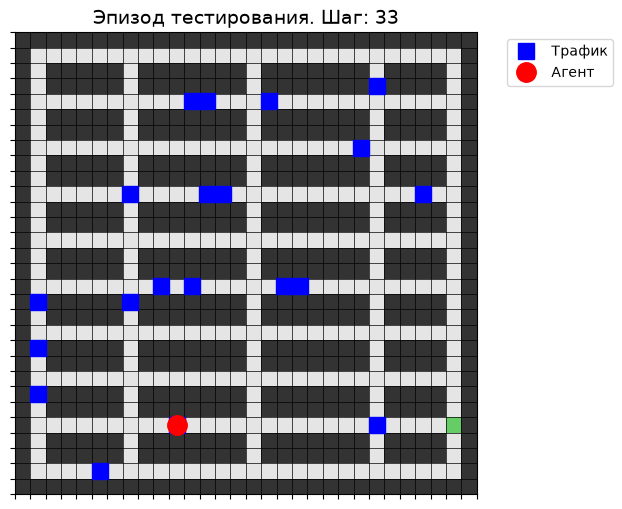

Тестирование завершено на шаге 33. Статус: crash


In [8]:
# ==========================================
# Тестирование BFS-стратегии с живой отрисовкой
# ==========================================
print("Начинаем тестирование BFS стратегии...")

planner = BFSPlanner(env)
env.reset(np.random.choice(len(env.start_positions))) #[cite: 1]
done = False

drawer = Draw_Grid(env)
step = 0
max_test_steps = 300

while not done and step < max_test_steps:
    # 1. Отрисовываем текущий кадр
    drawer.render_frame(step)
    clear_output(wait=True)
    display(drawer.fig)
    time.sleep(0.2)

    # 2. Получаем шаг от BFS планировщика
    action = planner.get_action(env.agent_pos)
    
    # 3. Делаем шаг в среде
    observ, reward, done, info = env.step(action) #[cite: 1]
    
    step += 1

# Финальный кадр
drawer.render_frame(step)
clear_output(wait=True)
display(drawer.fig)
plt.close(drawer.fig)

print(f"Тестирование завершено на шаге {step}. Статус: {info.get('status', 'done')}")